# Diagnóstico de overfitting y underfitting — XGBoost

## Resumen y contexto

Este análisis examina el modelo XGBoost de conteos mensuales de incidentes por parroquia desarrollado en `entrenamiento_predicion_mes_1.0.ipynb`. El objetivo de predicción es el número de incidentes reportados; la validación se realiza en 2024 y el año completo 2025 se conserva como prueba temporal final.

El CSV contiene 17.68 millones de registros (julio de 2021–agosto de 2026). La lectura se hace por bloques y los registros se agregan a parroquia-mes. El objetivo de este notebook es observar pérdidas y scores durante el boosting, comparar curvas de aprendizaje y complejidad, cuantificar la brecha entrenamiento-validación e implementar medidas contra el sobreajuste.

**Límites de interpretación:** se modela el volumen de incidentes reportados, no el riesgo individual de turistas. No se cuenta con población expuesta, afluencia turística ni medida de subregistro. Los diagnósticos de ajuste describen generalización dentro de esta validación temporal y no prueban causalidad ni calidad de una alerta operacional.

## Metodología

- **Misma formulación:** regresión de conteos con `count:poisson`, estacionalidad, tendencia y rezagos 1, 3 y 12 meses; provincia, cantón y parroquia se codifican como categorías.
- **Partición cronológica:** entrenamiento hasta diciembre de 2023, validación enero–diciembre de 2024, prueba final enero–diciembre de 2025. La métrica de prueba solo se calcula después de escoger la estrategia con validación.
- **Tracking por boosting:** XGBoost registra MAE de train y validación en cada árbol; se derivan R² en puntos de control para mostrar también una curva de score. No existe “accuracy” para una regresión de conteos.
- **Curvas temporales:** se implementan equivalentes cronológicamente seguros a las curvas de aprendizaje y validación de scikit-learn. La validación cruzada aleatoria estándar no es apropiada porque mezclaría meses pasados y futuros.
- **Mejoras evaluadas:** (1) parada temprana según MAE de 2024 y (2) menor complejidad y mayor regularización. Se comparan con el modelo base sobre idéntica validación y, tras seleccionar, se evalúa una sola vez en 2025.
- El PDF técnico se genera desde una celda del notebook y contiene resumen ejecutivo, metodología, diagnóstico, curvas, resultados, recomendaciones y referencias.

In [6]:
# Importamos las herramientas para análisis, gráficos, seguimiento y el modelo.
from pathlib import Path
from collections import Counter
from math import ceil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display, Markdown
from matplotlib.backends.backend_pdf import PdfPages
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

# Establecemos parámetros reproducibles para los experimentos.
RANDOM_STATE = 42
CHUNK_SIZE = 250_000
MAX_BOOSTING_ROUNDS = 500
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 120, 'savefig.dpi': 300})
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 140)

# Buscamos el CSV en la ruta habitual del proyecto y en rutas relativas.
DATASET_PATH = Path(r'C:\Users\PAULA\Documents\IntegradorG3\data\processed\dataset_proyecto_preparado.csv')
if not DATASET_PATH.exists():
    path_candidates = [
        Path.cwd() / 'data' / 'processed' / 'dataset_proyecto_preparado.csv',
        Path.cwd().parent / 'data' / 'processed' / 'dataset_proyecto_preparado.csv',
    ]
    DATASET_PATH = next((path for path in path_candidates if path.exists()), DATASET_PATH)

# Detenemos la ejecución con una ruta clara si no se localiza el archivo.
if not DATASET_PATH.exists():
    raise FileNotFoundError(f'No se encontró el CSV. Ajuste DATASET_PATH: {DATASET_PATH}')

print(f'Archivo: {DATASET_PATH}')
print(f'Tamaño: {DATASET_PATH.stat().st_size / (1024**3):.2f} GB')

Archivo: C:\Users\PAULA\Documents\IntegradorG3\data\processed\dataset_proyecto_preparado.csv
Tamaño: 2.17 GB


## 1. Carga y exploración del dataset

Se conserva la agregación de la práctica original: provincia, cantón, parroquia, año y mes. Las variables de un incidente concreto (`Servicio`, `Subtipo`, día de semana y día acumulado) se excluyen para evitar usar información posterior al pronóstico.

Filas leídas: 17,680,253; filas con período inválido: 0
Conteos parroquia-mes: 61,774; ubicaciones: 1,053
Cobertura: 2021-07 a 2026-08


,columna,valores_ausentes
0,provincia,0
1,Canton,0
2,Parroquia,0
3,Mes,0
4,Anio,0


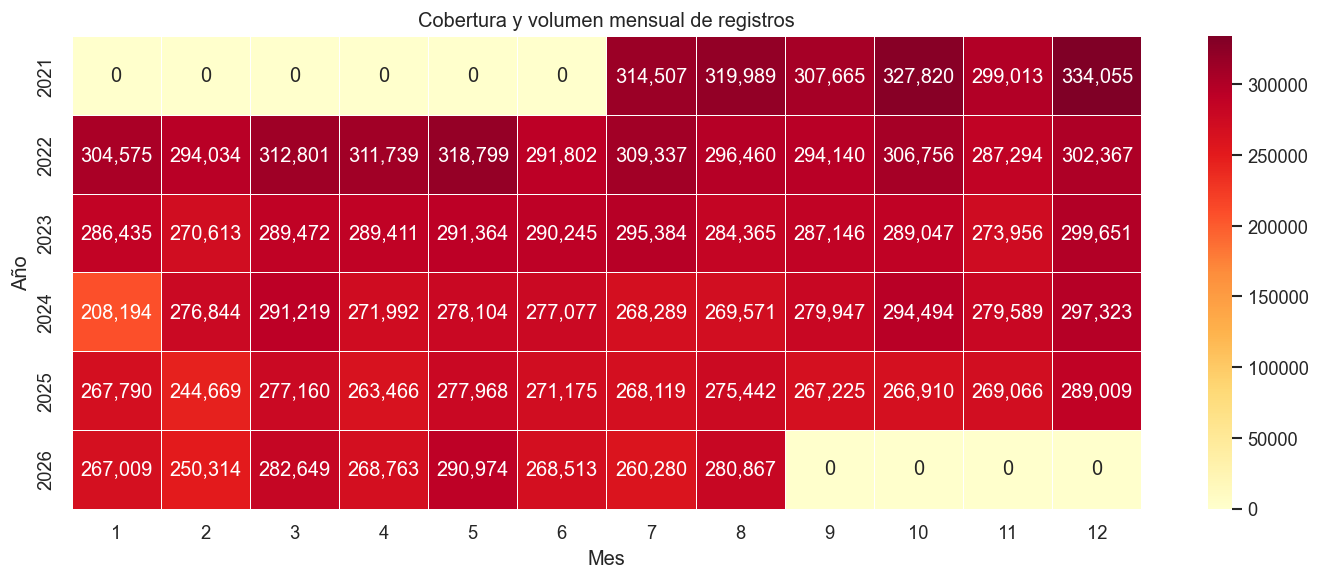

In [7]:
# Definimos las columnas necesarias para construir las series de conteos.
GEO_COLUMNS = ['provincia', 'Canton', 'Parroquia']
READ_COLUMNS = GEO_COLUMNS + ['Mes', 'Anio']

# Inicializamos acumuladores de agregados pequeños para el procesamiento por bloques.
partial_aggregates = []
missing_counts = Counter()
year_month_counts = Counter()
total_rows = 0
invalid_period_rows = 0

# Leemos solo las columnas relevantes y acotamos el tamaño de cada bloque.
for chunk in pd.read_csv(
    DATASET_PATH,
    usecols=READ_COLUMNS,
    chunksize=CHUNK_SIZE,
    encoding='utf-8-sig',
    low_memory=False,
    dtype={column: 'string' for column in GEO_COLUMNS},
):
    total_rows += len(chunk)
    missing_counts.update(chunk.isna().sum().to_dict())

    # Normalizamos categorías geográficas vacías y valores ausentes.
    for column in GEO_COLUMNS:
        chunk[column] = chunk[column].fillna('SIN DATO').str.strip().replace('', 'SIN DATO')

    # Convertimos el período a números y excluimos fechas que no sean válidas.
    chunk['Anio'] = pd.to_numeric(chunk['Anio'], errors='coerce')
    chunk['Mes'] = pd.to_numeric(chunk['Mes'], errors='coerce')
    valid_period = chunk['Anio'].notna() & chunk['Mes'].between(1, 12)
    invalid_period_rows += int((~valid_period).sum())
    valid_chunk = chunk.loc[valid_period].copy()
    valid_chunk['Anio'] = valid_chunk['Anio'].astype('int16')
    valid_chunk['Mes'] = valid_chunk['Mes'].astype('int8')

    # Acumulamos cobertura anual y mensual para identificar períodos parciales.
    year_month_counts.update(valid_chunk.groupby(['Anio', 'Mes'], observed=True).size().to_dict())

    # Agregamos cada bloque a conteos mensuales por parroquia.
    partial = (
        valid_chunk.groupby(GEO_COLUMNS + ['Anio', 'Mes'], observed=True, dropna=False)
        .size()
        .rename('target_count')
        .reset_index()
    )
    partial_aggregates.append(partial)

# Combinamos los agregados parciales en una sola serie parroquia-mes.
monthly_observations = (
    pd.concat(partial_aggregates, ignore_index=True)
    .groupby(GEO_COLUMNS + ['Anio', 'Mes'], as_index=False, observed=True)['target_count']
    .sum()
)
monthly_observations['period'] = pd.PeriodIndex(
    pd.to_datetime(dict(year=monthly_observations['Anio'], month=monthly_observations['Mes'], day=1)), freq='M'
)

# Mostramos calidad básica, volumen y cobertura observada.
quality_table = pd.DataFrame({'columna': list(missing_counts), 'valores_ausentes': list(missing_counts.values())})
print(f'Filas leídas: {total_rows:,}; filas con período inválido: {invalid_period_rows:,}')
print(f'Conteos parroquia-mes: {len(monthly_observations):,}; ubicaciones: {monthly_observations[GEO_COLUMNS].drop_duplicates().shape[0]:,}')
print(f'Cobertura: {monthly_observations["period"].min()} a {monthly_observations["period"].max()}')
display(quality_table)

# Graficamos conteos mensuales nacionales para visualizar cobertura y estacionalidad.
coverage = (
    pd.Series(year_month_counts, name='incidentes')
    .rename_axis(['Anio', 'Mes'])
    .reset_index()
    .pivot(index='Anio', columns='Mes', values='incidentes')
    .reindex(columns=range(1, 13))
    .fillna(0)
)
fig_coverage, ax = plt.subplots(figsize=(12, 5))
sns.heatmap(coverage, cmap='YlOrRd', annot=True, fmt=',.0f', linewidths=0.3, ax=ax)
ax.set_title('Cobertura y volumen mensual de registros')
ax.set_xlabel('Mes')
ax.set_ylabel('Año')
plt.tight_layout()
plt.show()

## 2. Variables temporales y división cronológica

Se conserva la evaluación del modelo original: entrenamiento hasta 2023, validación 2024 y prueba 2025. Para limitar la fuga por parroquias no conocidas al entrenar, se evalúan ubicaciones con reportes registrados hasta diciembre de 2023. Los meses anteriores a la primera observación de cada parroquia no se convierten en ceros.

In [8]:
# Declaramos límites de entrenamiento, validación y prueba temporal.
TRAIN_CUTOFF = pd.Period('2023-12', freq='M')
VALIDATION_YEAR = 2024
TEST_YEAR = 2025
first_reporting = monthly_observations.groupby(GEO_COLUMNS, as_index=False, observed=True)['period'].min()
known_locations = first_reporting.loc[first_reporting['period'] <= TRAIN_CUTOFF, GEO_COLUMNS]

# Construimos un panel mensual hasta el final de la cobertura disponible.
observed_periods = monthly_observations['period'].unique()
full_calendar = pd.period_range(min(observed_periods), max(observed_periods), freq='M')
calendar_frame = pd.DataFrame({'period': full_calendar})
calendar_frame['Anio'] = calendar_frame['period'].dt.year.astype('int16')
calendar_frame['Mes'] = calendar_frame['period'].dt.month.astype('int8')
panel = known_locations.merge(calendar_frame, how='cross')
panel = panel.merge(first_reporting.rename(columns={'period': 'first_reporting_period'}), on=GEO_COLUMNS, how='left', validate='many_to_one')
panel = panel.loc[panel['period'] >= panel['first_reporting_period']].copy()
panel = panel.merge(
    monthly_observations[GEO_COLUMNS + ['period', 'target_count']],
    on=GEO_COLUMNS + ['period'],
    how='left',
    validate='one_to_one',
)
panel['target_count'] = panel['target_count'].fillna(0).astype('float32')
panel = panel.sort_values(GEO_COLUMNS + ['period']).reset_index(drop=True)

# Calculamos rezagos y promedios usando exclusivamente meses anteriores.
location_group = panel.groupby(GEO_COLUMNS, sort=False, observed=True)['target_count']
panel['lag_1'] = location_group.shift(1)
panel['lag_3'] = location_group.shift(3)
panel['lag_12'] = location_group.shift(12)
panel['mean_previous_3'] = location_group.transform(lambda values: values.shift(1).rolling(3, min_periods=1).mean())
panel['mean_previous_12'] = location_group.transform(lambda values: values.shift(1).rolling(12, min_periods=1).mean())

# Representamos el mes como ciclo y el tiempo con una tendencia numérica.
panel['month_sin'] = np.sin(2 * np.pi * panel['Mes'] / 12)
panel['month_cos'] = np.cos(2 * np.pi * panel['Mes'] / 12)
panel['month_trend'] = panel['period'].map(lambda value: value.ordinal - full_calendar[0].ordinal).astype('int16')

# Exigimos un ciclo anual previo para disponer de lag 12 antes de modelar.
model_start = full_calendar[0] + 12
panel_model = panel.loc[panel['period'] >= model_start].copy()
train_mask = panel_model['period'] <= TRAIN_CUTOFF
validation_mask = panel_model['period'].dt.year == VALIDATION_YEAR
test_mask = panel_model['period'].dt.year == TEST_YEAR
train_frame = panel_model.loc[train_mask].copy()
validation_frame = panel_model.loc[validation_mask].copy()
train_validation_frame = panel_model.loc[train_mask | validation_mask].copy()
test_frame = panel_model.loc[test_mask].copy()

# Confirmamos que 2025 sea un período de prueba completo antes de continuar.
expected_test_periods = list(pd.period_range('2025-01', '2025-12', freq='M'))
if sorted(test_frame['period'].unique()) != expected_test_periods:
    raise ValueError('La prueba debe contener los doce meses de 2025.')
split_table = pd.DataFrame({
    'conjunto': ['Entrenamiento', 'Validación', 'Prueba final'],
    'período': [
        f'{train_frame.period.min()} a {train_frame.period.max()}',
        f'{validation_frame.period.min()} a {validation_frame.period.max()}',
        f'{test_frame.period.min()} a {test_frame.period.max()}',
    ],
    'filas': [len(train_frame), len(validation_frame), len(test_frame)],
})
display(split_table)
print(f'Ubicaciones conocidas al cierre de 2023: {len(known_locations):,}')

,conjunto,período,filas
0,Entrenamiento,2022-07 a 2023-12,18918
1,Validación,2024-01 a 2024-12,12612
2,Prueba final,2025-01 a 2025-12,12612


Ubicaciones conocidas al cierre de 2023: 1,051


## 3. Preprocesamiento y tracking de métricas

Las variables geográficas se convierten a una matriz dispersa one-hot y las variables numéricas se imputan con su mediana. Para cada iteración se registra MAE de train y validación. En regresión también calculamos R² en checkpoints, pues accuracy es una métrica de clasificación.

In [9]:
# Definimos predictores no geográficos y categorías geográficas.
NUMERIC_FEATURES = ['month_sin', 'month_cos', 'month_trend', 'lag_1', 'lag_3', 'lag_12', 'mean_previous_3', 'mean_previous_12']
FEATURES = GEO_COLUMNS + NUMERIC_FEATURES

# Construimos un preprocesador reproducible para las categorías y variables numéricas.
def build_preprocessor():
    return ColumnTransformer(
        transformers=[
            ('geografia', OneHotEncoder(handle_unknown='ignore', sparse_output=True, dtype=np.float32), GEO_COLUMNS),
            ('numericas', SimpleImputer(strategy='median'), NUMERIC_FEATURES),
        ],
        remainder='drop',
        sparse_threshold=0.3,
        verbose_feature_names_out=False,
    )

# Ajustamos el preprocesador solamente con entrenamiento y transformamos validación y prueba.
preprocessor = build_preprocessor()
X_train = preprocessor.fit_transform(train_frame[FEATURES])
X_validation = preprocessor.transform(validation_frame[FEATURES])
X_test = preprocessor.transform(test_frame[FEATURES])
y_train = train_frame['target_count'].to_numpy(dtype=np.float32)
y_validation = validation_frame['target_count'].to_numpy(dtype=np.float32)
y_test = test_frame['target_count'].to_numpy(dtype=np.float32)
print(f'Matriz X_train: {X_train.shape}; almacenamiento: {type(X_train).__name__}')

# Definimos métricas compatibles con conteos no negativos.
def regression_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.clip(np.asarray(predicted, dtype=float), 0, None)
    return {
        'MAE': mean_absolute_error(actual, predicted),
        'RMSE': np.sqrt(mean_squared_error(actual, predicted)),
        'R2': r2_score(actual, predicted),
        'WAPE (%)': 100 * np.abs(actual - predicted).sum() / max(actual.sum(), 1),
    }

# Definimos parámetros compartidos para que las comparaciones sean coherentes.
COMMON_PARAMS = {
    'objective': 'count:poisson',
    'eval_metric': 'mae',
    'learning_rate': 0.04,
    'tree_method': 'hist',
    'n_jobs': -1,
    'random_state': RANDOM_STATE,
}

# Imprimimos referencia estacional de validación calculada con información disponible hasta 2023.
validation_baseline = regression_metrics(y_validation, validation_frame['lag_12'].to_numpy())
display(pd.DataFrame([validation_baseline], index=['Lag 12 en validación 2024']).round(4))

Matriz X_train: (18918, 1239); almacenamiento: csr_matrix


,MAE,RMSE,R2,WAPE (%)
Lag 12 en validación 2024,37.4068,331.3771,0.9774,14.3282


## 4. Entrenamiento base con logging

El modelo base conserva los parámetros del experimento XGBoost precedente (profundidad 6, `min_child_weight=5`, muestreo y regularización L2) y ejecuta un límite de árboles sin parada temprana para exponer qué ocurre cuando sigue creciendo. El conjunto de validación participa en el tracking, no en el cálculo del gradiente.

In [10]:
# Configuramos el modelo base sin parada temprana para observar la curva completa.
base_params = {
    'max_depth': 6,
    'min_child_weight': 5,
    'subsample': 0.85,
    'colsample_bytree': 0.85,
    'reg_lambda': 5.0,
    'reg_alpha': 0.0,
}
base_model = XGBRegressor(**COMMON_PARAMS, **base_params, n_estimators=MAX_BOOSTING_ROUNDS)

# Registramos MAE en train y validación para cada árbol.
base_model.fit(
    X_train,
    y_train,
    eval_set=[(X_train, y_train), (X_validation, y_validation)],
    verbose=False,
)
eval_history = base_model.evals_result()
train_mae_curve = np.asarray(eval_history['validation_0']['mae'], dtype=float)
validation_mae_curve = np.asarray(eval_history['validation_1']['mae'], dtype=float)
best_round = int(np.argmin(validation_mae_curve) + 1)
best_validation_mae = float(validation_mae_curve[best_round - 1])

# Calculamos scores R² en checkpoints para seguir la calidad de ajuste durante el boosting.
checkpoint_rounds = sorted(set([1, 5, 10] + list(range(20, len(train_mae_curve) + 1, 20)) + [best_round, len(train_mae_curve)]))
score_tracking = []
for round_number in checkpoint_rounds:
    train_prediction_at_round = base_model.predict(X_train, iteration_range=(0, round_number))
    validation_prediction_at_round = base_model.predict(X_validation, iteration_range=(0, round_number))
    score_tracking.append({
        'iteración': round_number,
        'R2_train': r2_score(y_train, train_prediction_at_round),
        'R2_validación': r2_score(y_validation, validation_prediction_at_round),
    })
score_tracking = pd.DataFrame(score_tracking)

# Construimos un registro resumido de métricas y generalización en el mejor punto de validación.
base_train_prediction = base_model.predict(X_train, iteration_range=(0, best_round))
base_validation_prediction = base_model.predict(X_validation, iteration_range=(0, best_round))
base_train_metrics = regression_metrics(y_train, base_train_prediction)
base_validation_metrics = regression_metrics(y_validation, base_validation_prediction)
generalization_gap = base_validation_metrics['MAE'] - base_train_metrics['MAE']
gap_ratio = base_validation_metrics['MAE'] / max(base_train_metrics['MAE'], 1e-9)
tracking_summary = pd.DataFrame([
    {'conjunto': 'Train', **base_train_metrics},
    {'conjunto': 'Validación 2024', **base_validation_metrics},
])
print(f'Mejor iteración según MAE de validación: {best_round} de {len(validation_mae_curve)}')
print(f'Brecha MAE validación - train: {generalization_gap:.3f}; razón validación/train: {gap_ratio:.3f}')
display(tracking_summary.round(4))
display(score_tracking.tail(10).round(4))

Mejor iteración según MAE de validación: 288 de 500
Brecha MAE validación - train: 11.378; razón validación/train: 1.739


,conjunto,MAE,RMSE,R2,WAPE (%)
0,Train,15.3965,92.4504,0.9982,5.5550
1,Validación 2024,26.7749,281.4289,0.9837,10.2557


,iteración,R2_train,R2_validación
19,320,0.9993,0.9839
20,340,0.9995,0.9839
21,360,0.9996,0.9838
22,380,0.9997,0.9837
23,400,0.9997,0.9836
24,420,0.9998,0.9836
25,440,0.9998,0.9836
26,460,0.9998,0.9836
27,480,0.9998,0.9836
28,500,0.9998,0.9836


## 5. Curvas de aprendizaje y score

La pérdida es MAE: un valor menor indica menor error típico por parroquia-mes. La curva de score es R²: puede ser negativa y no tiene un equivalente de accuracy para este problema. El MAE train suele seguir descendiendo al aumentar árboles; se diagnostica sobreajuste cuando ese descenso no se acompaña de validación.

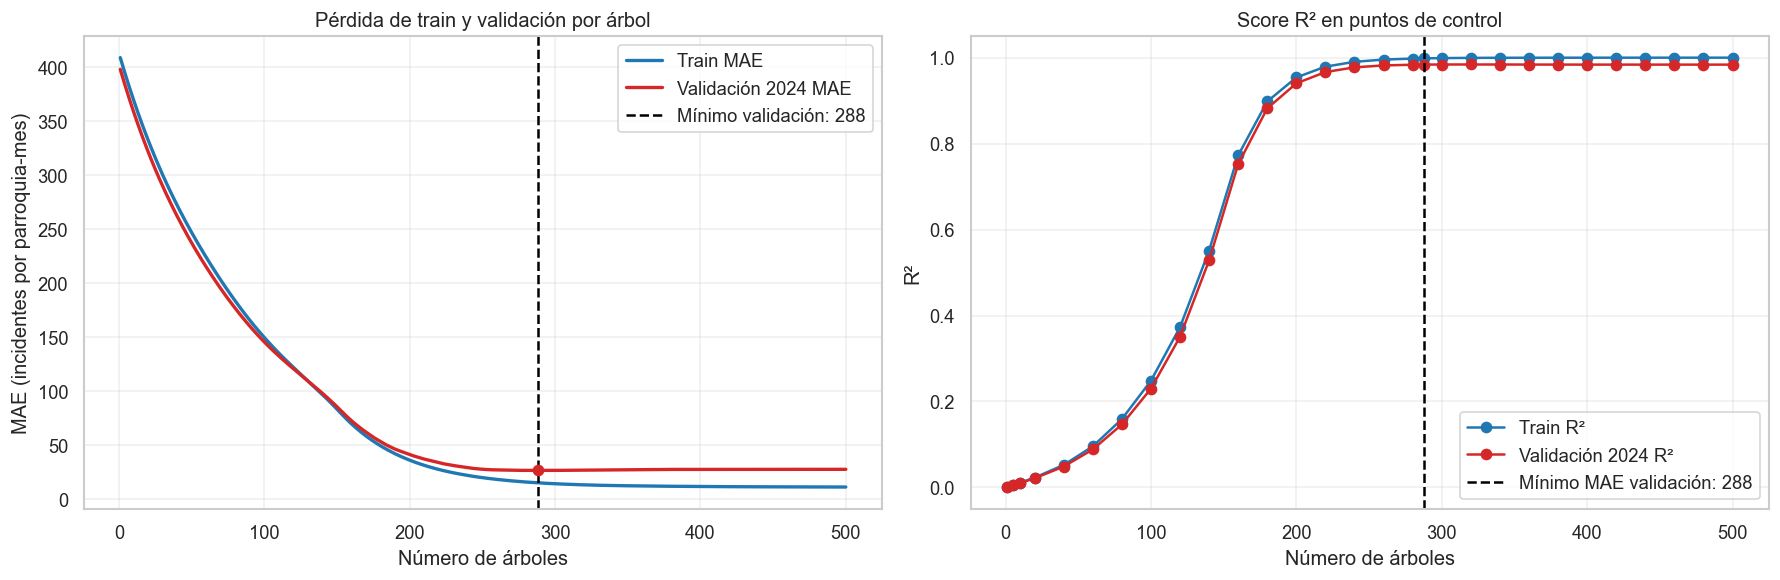

Deterioro de MAE validación después del mínimo (ventana final): 4.00%
Cambio de MAE train en la misma ventana: -25.16%


In [11]:
# Preparamos ejes compartidos para pérdida y score a lo largo de las iteraciones.
round_numbers = np.arange(1, len(train_mae_curve) + 1)
fig_loss, axes = plt.subplots(1, 2, figsize=(15, 5))

# Graficamos MAE de entrenamiento y validación con anotación del mínimo validado.
axes[0].plot(round_numbers, train_mae_curve, color='#1f77b4', label='Train MAE', linewidth=2)
axes[0].plot(round_numbers, validation_mae_curve, color='#d62728', label='Validación 2024 MAE', linewidth=2)
axes[0].axvline(best_round, color='black', linestyle='--', label=f'Mínimo validación: {best_round}')
axes[0].scatter([best_round], [best_validation_mae], color='#d62728', zorder=5)
axes[0].set_title('Pérdida de train y validación por árbol')
axes[0].set_xlabel('Número de árboles')
axes[0].set_ylabel('MAE (incidentes por parroquia-mes)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Graficamos R² en los checkpoints usando los mismos colores contrastantes.
axes[1].plot(score_tracking['iteración'], score_tracking['R2_train'], marker='o', color='#1f77b4', label='Train R²')
axes[1].plot(score_tracking['iteración'], score_tracking['R2_validación'], marker='o', color='#d62728', label='Validación 2024 R²')
axes[1].axvline(best_round, color='black', linestyle='--', label=f'Mínimo MAE validación: {best_round}')
axes[1].set_title('Score R² en puntos de control')
axes[1].set_xlabel('Número de árboles')
axes[1].set_ylabel('R²')
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Cuantificamos si la validación empeoró después de su mejor iteración.
late_window = min(30, max(1, len(validation_mae_curve) - best_round))
late_validation_mae = float(np.mean(validation_mae_curve[-late_window:])) if best_round < len(validation_mae_curve) else best_validation_mae
late_train_mae = float(np.mean(train_mae_curve[-late_window:])) if best_round < len(train_mae_curve) else float(train_mae_curve[-1])
validation_degradation_pct = 100 * (late_validation_mae - best_validation_mae) / max(best_validation_mae, 1e-9)
train_late_change_pct = 100 * (late_train_mae - train_mae_curve[best_round - 1]) / max(train_mae_curve[best_round - 1], 1e-9)
print(f'Deterioro de MAE validación después del mínimo (ventana final): {validation_degradation_pct:.2f}%')
print(f'Cambio de MAE train en la misma ventana: {train_late_change_pct:.2f}%')

## 6. Curvas por tamaño de entrenamiento y complejidad

Para la curva de aprendizaje se amplía cronológicamente el historial de entrenamiento y se mantiene fija la validación 2024. Para la curva de validación se comparan profundidades de árbol con el mismo número de iteraciones. Estas son implementaciones temporales propias en lugar de los `learning_curve` y `validation_curve` genéricos: los pliegues aleatorios de sus configuraciones habituales mezclarían pasado y futuro.

,meses_entrenamiento,filas_entrenamiento,MAE_train,MAE_validación
0,6,6306,126.278,120.380
1,12,12612,123.479,121.072
2,18,18918,123.260,121.865


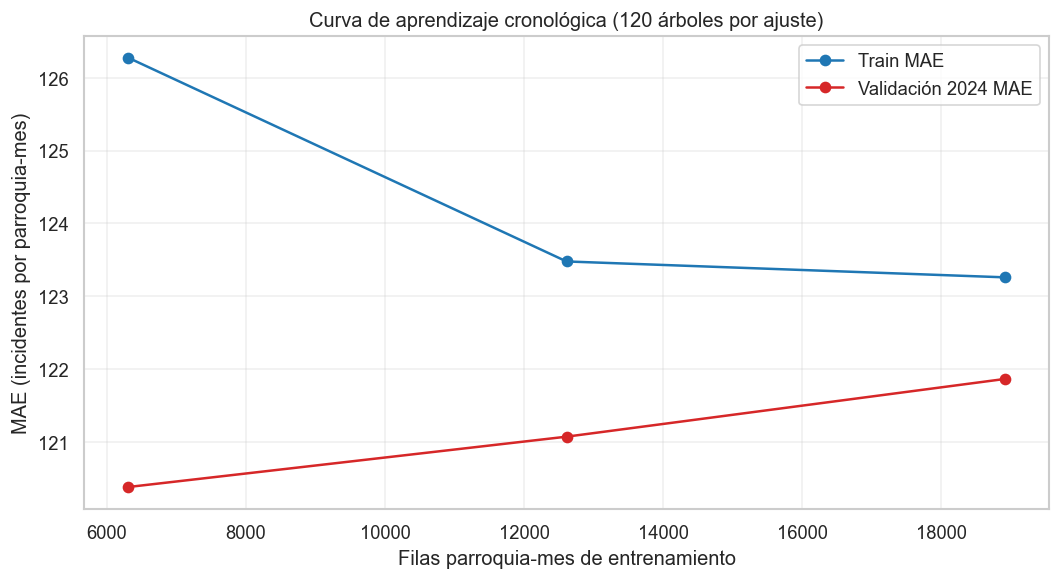

,max_depth,MAE_train,MAE_validación,R2_validación
0,3,125.687,124.218,0.35
1,6,122.123,121.069,0.35
2,9,121.078,121.228,0.35


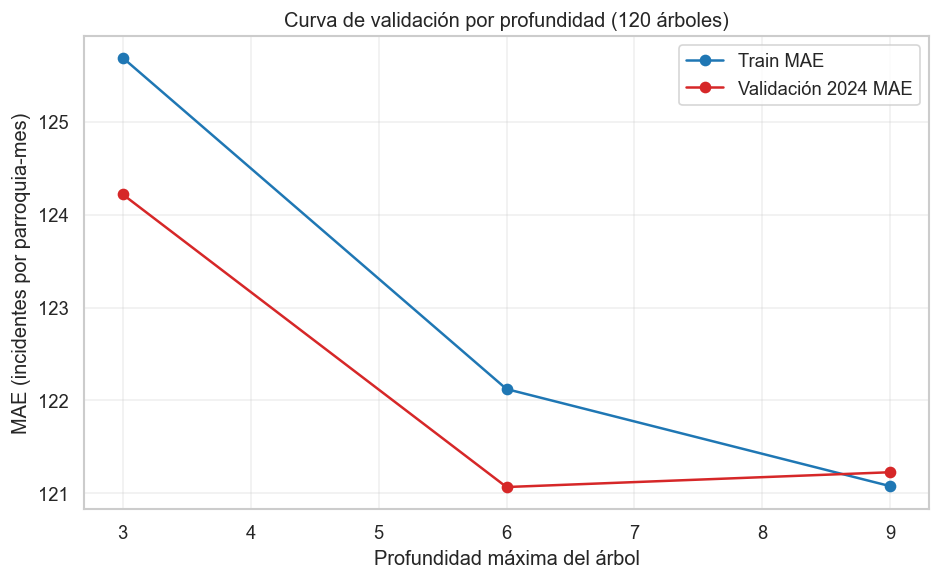

In [12]:
# Preparamos cortes cronológicos que mantienen meses completos en cada tamaño de muestra.
available_train_periods = sorted(train_frame['period'].unique())
learning_period_counts = sorted(set([max(3, len(available_train_periods) // 3), max(6, 2 * len(available_train_periods) // 3), len(available_train_periods)]))
learning_records = []
learning_rounds = min(120, best_round)

# Ajustamos el mismo modelo regularizado en ventanas temporales cada vez mayores.
learning_params = {
    'max_depth': 4,
    'min_child_weight': 10,
    'subsample': 0.8,
    'colsample_bytree': 0.8,
    'reg_lambda': 10.0,
    'reg_alpha': 1.0,
}
for period_count in learning_period_counts:
    cutoff = available_train_periods[period_count - 1]
    size_mask = train_frame['period'] <= cutoff
    size_model = XGBRegressor(**COMMON_PARAMS, **learning_params, n_estimators=learning_rounds)
    size_model.fit(X_train[size_mask.to_numpy()], y_train[size_mask.to_numpy()], verbose=False)
    size_train_prediction = size_model.predict(X_train[size_mask.to_numpy()])
    size_validation_prediction = size_model.predict(X_validation)
    learning_records.append({
        'meses_entrenamiento': period_count,
        'filas_entrenamiento': int(size_mask.sum()),
        'MAE_train': mean_absolute_error(y_train[size_mask.to_numpy()], size_train_prediction),
        'MAE_validación': mean_absolute_error(y_validation, size_validation_prediction),
    })
learning_curve_table = pd.DataFrame(learning_records).drop_duplicates('meses_entrenamiento').sort_values('meses_entrenamiento')
display(learning_curve_table.round(3))

# Graficamos las curvas de MAE para diferentes tamaños de historia.
fig_learning, ax = plt.subplots(figsize=(9, 5))
ax.plot(learning_curve_table['filas_entrenamiento'], learning_curve_table['MAE_train'], marker='o', color='#1f77b4', label='Train MAE')
ax.plot(learning_curve_table['filas_entrenamiento'], learning_curve_table['MAE_validación'], marker='o', color='#d62728', label='Validación 2024 MAE')
ax.set_title(f'Curva de aprendizaje cronológica ({learning_rounds} árboles por ajuste)')
ax.set_xlabel('Filas parroquia-mes de entrenamiento')
ax.set_ylabel('MAE (incidentes por parroquia-mes)')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Comparamos profundidades con igual número de árboles y los mismos datos temporales.
validation_rounds = min(120, best_round)
depth_records = []
for depth in [3, 6, 9]:
    depth_params = {**learning_params, 'max_depth': depth}
    depth_model = XGBRegressor(**COMMON_PARAMS, **depth_params, n_estimators=validation_rounds)
    depth_model.fit(X_train, y_train, verbose=False)
    train_prediction = depth_model.predict(X_train)
    validation_prediction = depth_model.predict(X_validation)
    depth_records.append({
        'max_depth': depth,
        'MAE_train': mean_absolute_error(y_train, train_prediction),
        'MAE_validación': mean_absolute_error(y_validation, validation_prediction),
        'R2_validación': r2_score(y_validation, validation_prediction),
    })
depth_curve_table = pd.DataFrame(depth_records)
display(depth_curve_table.round(3))

# Graficamos la curva de validación para complejidad de árbol.
fig_validation, ax = plt.subplots(figsize=(8, 5))
ax.plot(depth_curve_table['max_depth'], depth_curve_table['MAE_train'], marker='o', color='#1f77b4', label='Train MAE')
ax.plot(depth_curve_table['max_depth'], depth_curve_table['MAE_validación'], marker='o', color='#d62728', label='Validación 2024 MAE')
ax.set_title(f'Curva de validación por profundidad ({validation_rounds} árboles)')
ax.set_xlabel('Profundidad máxima del árbol')
ax.set_ylabel('MAE (incidentes por parroquia-mes)')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Diagnóstico sistemático y cuantitativo

Un gap por sí solo no demuestra overfitting: en datos muy heterogéneos puede existir un MAE train menor por construcción. Se considera evidencia más sólida que la validación empeore al seguir entrenando mientras train continúa mejorando. Para underfitting se contrasta el MAE de ambos conjuntos con el baseline estacional `lag_12`; los umbrales son heurísticos y deben interpretarse en el contexto de los conteos.

In [13]:
# Comparamos el punto óptimo y el final para cuantificar el patrón de sobreajuste.
base_final_train = float(train_mae_curve[-1])
base_final_validation = float(validation_mae_curve[-1])
best_gap_ratio = base_validation_metrics['MAE'] / max(base_train_metrics['MAE'], 1e-9)
beats_baseline = base_validation_metrics['MAE'] < validation_baseline['MAE']
has_overfit_pattern = validation_degradation_pct >= 5 and train_late_change_pct < 0
both_poor = (
    base_train_metrics['MAE'] >= validation_baseline['MAE']
    and base_validation_metrics['MAE'] >= validation_baseline['MAE']
)

# Aplicamos reglas explícitas y conservadoras para etiquetar el comportamiento observado.
if has_overfit_pattern:
    diagnosis = 'Evidencia de overfitting al prolongar el boosting: la validación empeora mientras train sigue mejorando.'
elif both_poor and best_gap_ratio < 1.25:
    diagnosis = 'Posible underfitting: train y validación tienen errores altos y próximos al baseline estacional.'
elif beats_baseline and best_gap_ratio < 1.5:
    diagnosis = 'Generalización razonable en el mínimo de validación; revisar el gap y el comportamiento por período.'
else:
    diagnosis = 'Resultado mixto: hay gap o mejora limitada frente al baseline; no basta para afirmar overfitting ni underfitting.'

# Construimos una tabla compacta de señales cuantitativas.
diagnostic_table = pd.DataFrame([
    {'indicador': 'MAE train en mejor ronda', 'valor': base_train_metrics['MAE'], 'interpretación': 'Menor es mejor; error en incidentes por parroquia-mes'},
    {'indicador': 'MAE validación en mejor ronda', 'valor': base_validation_metrics['MAE'], 'interpretación': 'Estimación temporal de generalización en 2024'},
    {'indicador': 'Gap MAE (val - train)', 'valor': generalization_gap, 'interpretación': 'Gap positivo grande puede indicar ajuste específico a train'},
    {'indicador': 'Razón MAE (val / train)', 'valor': gap_ratio, 'interpretación': 'Comparación relativa entre error de validación y entrenamiento'},
    {'indicador': 'Deterioro validación tras mínimo (%)', 'valor': validation_degradation_pct, 'interpretación': 'Positivo con caída de train es señal de overfitting'},
    {'indicador': 'Cambio train en tramo final (%)', 'valor': train_late_change_pct, 'interpretación': 'Negativo significa que train siguió mejorando'},
    {'indicador': 'MAE baseline lag 12', 'valor': validation_baseline['MAE'], 'interpretación': 'Referencia estacional de validación'},
])
display(diagnostic_table.round(4))
display(Markdown(f'### Diagnóstico del modelo base\n\n**{diagnosis}**\n\nEn la ronda {best_round}, el MAE de validación fue {base_validation_metrics["MAE"]:.2f}, frente a {validation_baseline["MAE"]:.2f} del baseline `lag_12`. La brecha MAE val-train fue {generalization_gap:.2f}. Estas reglas son señales descriptivas, no una certificación automática del modelo.'))

,indicador,valor,interpretación
0,MAE train en mejor ronda,15.3965,Menor es mejor; error en incidentes por parroq...
1,MAE validación en mejor ronda,26.7749,Estimación temporal de generalización en 2024
2,Gap MAE (val - train),11.3784,Gap positivo grande puede indicar ajuste espec...
3,Razón MAE (val / train),1.7390,Comparación relativa entre error de validación...
4,Deterioro validación tras mínimo (%),3.9970,Positivo con caída de train es señal de overfi...
5,Cambio train en tramo final (%),-25.1605,Negativo significa que train siguió mejorando
6,MAE baseline lag 12,37.4068,Referencia estacional de validación


### Diagnóstico del modelo base

**Resultado mixto: hay gap o mejora limitada frente al baseline; no basta para afirmar overfitting ni underfitting.**

En la ronda 288, el MAE de validación fue 26.77, frente a 37.41 del baseline `lag_12`. La brecha MAE val-train fue 11.38. Estas reglas son señales descriptivas, no una certificación automática del modelo.

## 8. Estrategias de mejora y comparación antes/después

**Estrategia A — early stopping:** escoger el número de árboles que minimiza el MAE de validación; el entrenamiento base ya registró los valores necesarios sin inspeccionar la prueba. **Estrategia B — reducir complejidad y regularizar:** limitar profundidad, aumentar `min_child_weight` y L2, activar L1 y reducir la fracción de columnas. No aplican dropout ni aumento sintético de datos a árboles tabulares XGBoost; tampoco se debe aumentar el número de épocas si la validación ya empeora.

,estrategia,MAE,RMSE,R2,WAPE (%),MAE_train,árboles
0,Parada temprana (288 árboles),26.7749,281.4289,0.9837,10.2557,15.3965,288
1,Base sin parada (500 árboles),27.8495,282.2953,0.9836,10.6674,11.4771,500
2,Regularización + parada (294 árboles),27.9884,301.5369,0.9813,10.7205,17.7048,294


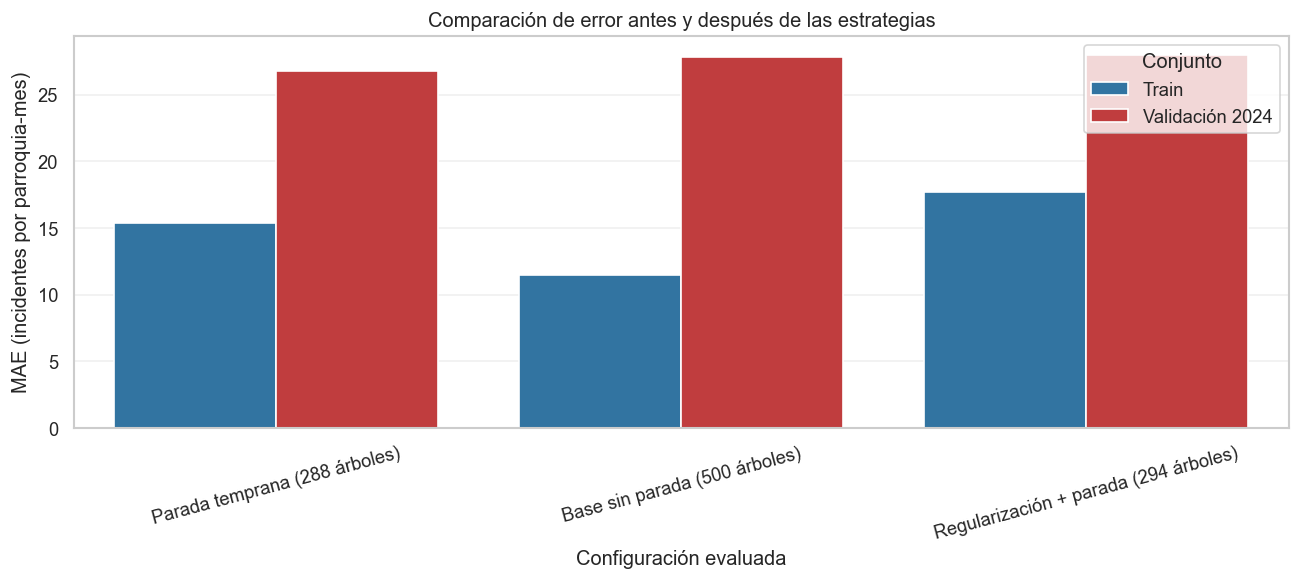

Estrategia seleccionada en validación: Parada temprana (288 árboles)


In [14]:
# Evaluamos el modelo base completo, su punto de parada y una variante de menor complejidad.
regularized_params = {
    'max_depth': 4,
    'min_child_weight': 10,
    'subsample': 0.8,
    'colsample_bytree': 0.75,
    'reg_lambda': 10.0,
    'reg_alpha': 1.0,
}
regularized_model = XGBRegressor(
    **COMMON_PARAMS,
    **regularized_params,
    n_estimators=MAX_BOOSTING_ROUNDS,
    early_stopping_rounds=35,
)

# Aplicamos parada temprana usando únicamente el MAE de validación 2024.
regularized_model.fit(
    X_train,
    y_train,
    eval_set=[(X_train, y_train), (X_validation, y_validation)],
    verbose=False,
)
regularized_best_round = int(regularized_model.best_iteration) + 1
regularized_eval = regularized_model.evals_result()
regularized_train_prediction = regularized_model.predict(X_train)
regularized_validation_prediction = regularized_model.predict(X_validation)
regularized_train_metrics = regression_metrics(y_train, regularized_train_prediction)
regularized_validation_metrics = regression_metrics(y_validation, regularized_validation_prediction)

# Calculamos predicciones del modelo base en el último árbol y en el mínimo de validación.
base_full_train_prediction = base_model.predict(X_train)
base_full_validation_prediction = base_model.predict(X_validation)
base_full_train_metrics = regression_metrics(y_train, base_full_train_prediction)
base_full_validation_metrics = regression_metrics(y_validation, base_full_validation_prediction)
strategy_rows = [
    {'estrategia': f'Base sin parada ({MAX_BOOSTING_ROUNDS} árboles)', **base_full_validation_metrics, 'MAE_train': base_full_train_metrics['MAE'], 'árboles': MAX_BOOSTING_ROUNDS},
    {'estrategia': f'Parada temprana ({best_round} árboles)', **base_validation_metrics, 'MAE_train': base_train_metrics['MAE'], 'árboles': best_round},
    {'estrategia': f'Regularización + parada ({regularized_best_round} árboles)', **regularized_validation_metrics, 'MAE_train': regularized_train_metrics['MAE'], 'árboles': regularized_best_round},
]
strategy_comparison = pd.DataFrame(strategy_rows).sort_values('MAE').reset_index(drop=True)
display(strategy_comparison.round(4))

# Comparamos visualmente error de entrenamiento y validación antes y después de las mejoras.
fig_comparison, ax = plt.subplots(figsize=(11, 5))
plot_comparison = strategy_comparison.melt(
    id_vars='estrategia',
    value_vars=['MAE_train', 'MAE'],
    var_name='conjunto',
    value_name='error_parroquia_mes',
)
plot_comparison['conjunto'] = plot_comparison['conjunto'].replace({'MAE_train': 'Train', 'MAE': 'Validación 2024'})
sns.barplot(data=plot_comparison, x='estrategia', y='error_parroquia_mes', hue='conjunto', palette=['#1f77b4', '#d62728'], ax=ax)
ax.set_title('Comparación de error antes y después de las estrategias')
ax.set_xlabel('Configuración evaluada')
ax.set_ylabel('MAE (incidentes por parroquia-mes)')
ax.tick_params(axis='x', rotation=15)
ax.legend(title='Conjunto')
ax.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# Seleccionamos la estrategia de menor MAE de validación para la evaluación final reservada.
selected_strategy = strategy_comparison.iloc[0]['estrategia']
if selected_strategy.startswith('Regularización'):
    final_params = regularized_params
    final_rounds = regularized_best_round
else:
    final_params = base_params
    final_rounds = best_round
print(f'Estrategia seleccionada en validación: {selected_strategy}')

## 9. Prueba temporal final y conclusión del diagnóstico

Una vez seleccionados parámetros e iteraciones con 2024, el modelo final vuelve a entrenarse con información hasta diciembre de 2024 y se mide una sola vez en 2025. Esta evaluación no sustituye validaciones con cohortes de años futuros.

In [15]:
# Volvemos a ajustar el preprocesador con todo el período permitido antes de la prueba.
preprocessor_final = build_preprocessor()
X_train_validation = preprocessor_final.fit_transform(train_validation_frame[FEATURES])
X_test_final = preprocessor_final.transform(test_frame[FEATURES])
y_train_validation = train_validation_frame['target_count'].to_numpy(dtype=np.float32)

# Entrenamos con hiperparámetros seleccionados y número de árboles fijado con validación.
final_model = XGBRegressor(**COMMON_PARAMS, **final_params, n_estimators=final_rounds)
final_model.fit(X_train_validation, y_train_validation, verbose=False)
test_prediction = np.clip(final_model.predict(X_test_final), 0, None)
test_metrics = regression_metrics(y_test, test_prediction)
test_baseline = regression_metrics(y_test, test_frame['lag_12'].to_numpy())
final_test_table = pd.DataFrame([
    {'modelo': 'XGBoost seleccionado', **test_metrics},
    {'modelo': 'Baseline lag 12', **test_baseline},
])
display(final_test_table.round(4))

# Resumimos la interpretación del entrenamiento y la prueba, evitando umbrales de negocio inventados.
selected_validation_mae = float(strategy_comparison.iloc[0]['MAE'])
improvement_vs_base_pct = 100 * (base_full_validation_metrics['MAE'] - selected_validation_mae) / max(base_full_validation_metrics['MAE'], 1e-9)
if has_overfit_pattern:
    diagnostic_conclusion = 'Se observó una señal de overfitting al continuar el boosting; el punto de parada y la variante regularizada se compararon con el mismo período de validación.'
elif both_poor:
    diagnostic_conclusion = 'El ajuste puede estar limitado por underfitting o por variables disponibles; ambas particiones rindieron cerca o peor que el baseline estacional.'
else:
    diagnostic_conclusion = 'Las curvas no muestran por sí solas una evidencia fuerte de underfitting; el gap y la estabilidad de validación son los indicadores clave para monitorizar.'
display(Markdown(
    f"### Conclusión ejecutiva\n\n"
    f"{diagnostic_conclusion}\n\n"
    f"- Mejor configuración según validación: **{selected_strategy}**.\n"
    f"- Cambio de MAE de validación frente al modelo base completo: **{improvement_vs_base_pct:.1f}%** (positivo significa menor MAE).\n"
    f"- MAE final en 2025: **{test_metrics['MAE']:.2f}**, frente a **{test_baseline['MAE']:.2f}** del baseline `lag_12`.\n"
    f"- El resultado 2025 se interpreta una sola vez y no debe usarse para volver a seleccionar hiperparámetros.\n\n"
    "La decisión final debe considerar RMSE, error por mes y desempeño en años adicionales. Los conteos reportados no equivalen a riesgo turístico."
))

,modelo,MAE,RMSE,R2,WAPE (%)
0,XGBoost seleccionado,22.8062,214.2165,0.9900,8.8913
1,Baseline lag 12,32.4531,263.4175,0.9849,12.6524


### Conclusión ejecutiva

Las curvas no muestran por sí solas una evidencia fuerte de underfitting; el gap y la estabilidad de validación son los indicadores clave para monitorizar.

- Mejor configuración según validación: **Parada temprana (288 árboles)**.
- Cambio de MAE de validación frente al modelo base completo: **3.9%** (positivo significa menor MAE).
- MAE final en 2025: **22.81**, frente a **32.45** del baseline `lag_12`.
- El resultado 2025 se interpreta una sola vez y no debe usarse para volver a seleccionar hiperparámetros.

La decisión final debe considerar RMSE, error por mes y desempeño en años adicionales. Los conteos reportados no equivalen a riesgo turístico.

## 10. Reporte técnico PDF

La celda siguiente produce `diagnostic_report.pdf` en el directorio de trabajo. El código fuente y la metodología permanecen íntegramente en este notebook. El reporte resume métricas y figuras generadas durante la ejecución.

In [16]:
# Definimos la ruta del reporte técnico solicitado.
REPORT_PATH = Path.cwd() / 'diagnostic_report.pdf'

# Creamos una página ejecutiva con metodología, diagnóstico y métricas principales.
executive_figure = plt.figure(figsize=(8.27, 11.69))
executive_axis = executive_figure.add_axes([0.08, 0.06, 0.84, 0.88])
executive_axis.axis('off')
executive_text = (
    'DIAGNÓSTICO DE OVERFITTING Y UNDERFITTING\n\n'
    'Resumen ejecutivo\n'
    f'Diagnóstico: {diagnosis}\n\n'
    f'Dataset: {total_rows:,} registros originales; agregación por provincia, cantón, parroquia y mes.\n'
    f'División temporal: train hasta {TRAIN_CUTOFF}; validación {VALIDATION_YEAR}; prueba final {TEST_YEAR}.\n'
    f'Ronda óptima base: {best_round} de {MAX_BOOSTING_ROUNDS}; MAE validación: {base_validation_metrics["MAE"]:.2f}; MAE train: {base_train_metrics["MAE"]:.2f}.\n'
    f'Gap MAE validación-train: {generalization_gap:.2f}; deterioro validación tras el mínimo: {validation_degradation_pct:.2f}%.\n'
    f'Estrategia seleccionada: {selected_strategy}; MAE de prueba 2025: {test_metrics["MAE"]:.2f}; baseline lag 12: {test_baseline["MAE"]:.2f}.\n\n'
    'Metodología\n'
    'Se agregaron los eventos mensuales por parroquia y se construyeron rezagos usando solo información pasada. '
    'El preprocesamiento geográfico se ajustó con entrenamiento. Se monitorizó MAE por iteración y R² en checkpoints; '
    'se usó 2024 para seleccionar iteraciones/regularización y 2025 se reservó hasta la evaluación final.\n\n'
    'Interpretación responsable\n'
    'Las curvas identifican patrones de ajuste y generalización, no causalidad. Los conteos reflejan reportes y no están '
    'normalizados por población o afluencia turística. No se debe interpretar el resultado como nivel individual de peligro.\n\n'
    'Estrategias implementadas\n'
    '1) Parada temprana por MAE de validación. 2) Menor profundidad, mayor min_child_weight, regularización L1/L2 y '
    'submuestreo de columnas/filas.\n\n'
    'Referencias técnicas\n'
    'Chen & Guestrin (2016), XGBoost: A Scalable Tree Boosting System. KDD.\n'
    'scikit-learn User Guide: Learning curves; TimeSeriesSplit y métricas de regresión.\n'
    'XGBoost Python API: eval_set, evals_result y early_stopping_rounds.'
)
executive_axis.text(0, 1, executive_text, va='top', ha='left', fontsize=10, linespacing=1.45, wrap=True)

# Guardamos resumen y curvas profesionales a 300 DPI en un documento multipágina.
with PdfPages(REPORT_PATH) as pdf:
    pdf.savefig(executive_figure, dpi=300, bbox_inches='tight')
    pdf.savefig(fig_loss, dpi=300, bbox_inches='tight')
    pdf.savefig(fig_learning, dpi=300, bbox_inches='tight')
    pdf.savefig(fig_validation, dpi=300, bbox_inches='tight')
    pdf.savefig(fig_comparison, dpi=300, bbox_inches='tight')
plt.close(executive_figure)
print(f'Reporte técnico guardado en: {REPORT_PATH.resolve()}')
print(f'Tamaño del PDF: {REPORT_PATH.stat().st_size / 1024:.1f} KB')

Reporte técnico guardado en: C:\Users\PAULA\Documents\IntegradorG3\notebooks\diagnostic_report.pdf
Tamaño del PDF: 40.9 KB


## Conclusiones y recomendaciones futuras

1. Un gap train-validación creciente y validación que empeora tras su mínimo son señales de overfitting; ambas pérdidas altas y próximas al baseline sugieren underfitting. El diagnóstico se debe apoyar en curvas, métricas y comparación temporal, no solo en una brecha puntual.
2. Early stopping limita árboles que no mejoran la validación. Reducir profundidad, elevar `min_child_weight`, aumentar L1/L2 y ajustar `subsample`/`colsample_bytree` son estrategias aplicables a árboles tabulares; dropout y aumento de imágenes no corresponden a este modelo.
3. Si train y validación siguen cerca del baseline, revisar variables disponibles, granularidad, cambios en los procesos de registro y cobertura de cada parroquia antes de aumentar complejidad.
4. Añadir ventanas de validación de origen rodante y años nuevos para comprobar estabilidad temporal. No retocar el modelo en función de la prueba 2025 ya informada.
5. Para evaluar riesgo para turistas, incorporar denominadores de exposición, datos de afluencia, incertidumbre y controles de subregistro, y validar resultados con expertos locales.

**Conclusión general:** este notebook registra y compara el comportamiento de XGBoost a lo largo del entrenamiento, implementa parada temprana y regularización como estrategias concretas y mantiene una prueba temporal independiente. Sus diagnósticos son evidencia empírica sobre ajuste predictivo de reportes mensuales, no una certificación de seguridad territorial.